Person Re-Identification 

The idea is to first establish a baseline model that performs the task of Person Re-Id.

To dos:
1- Perform object detection
2- Get embeddings of persons detected
3- Get embedding of query
4- A similarity metric for retrieval


In [ ]:
# lets get started with single image
image_path = "../archive/frames"
import os
# sample random image from the folder
import random
from IPython.display import display
from PIL import Image
%matplotlib inline



In [3]:
!pip install ultralytics


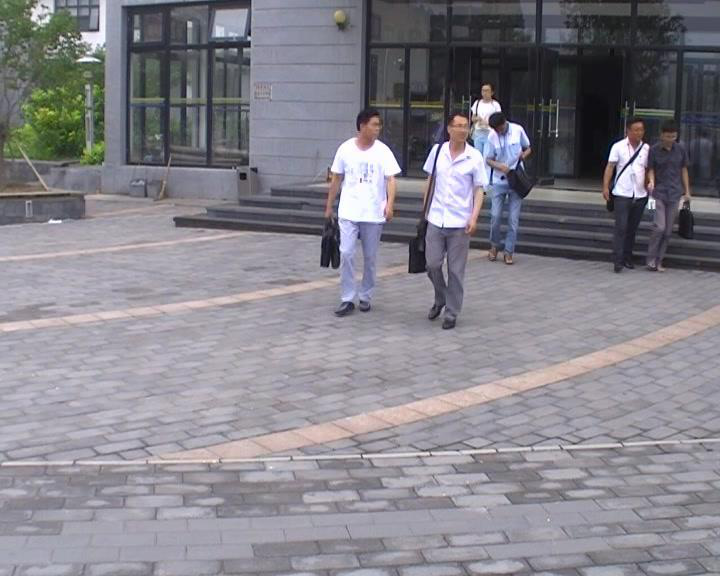

In [22]:
all_image_files = [os.path.join(image_path, f) for f in os.listdir(image_path) if f.endswith(".jpg")]
sample_image_file = random.choice(all_image_files)
image = Image.open(sample_image_file)
display(image)

In [16]:
subset_image_files = all_image_files[:10]  # taking first 10 images for testing

In [17]:

# time to run the model on the image
import time
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
# start_time = time.time()
# results = model(all_image_files[:10])
# end_time = time.time()
# print(f"Inference time: {end_time - start_time} seconds")   

# Lets make an empty list and applt the model on all images and store the results in the list
all_results = []
for img_file in subset_image_files:
    results = model(img_file)
    all_results.append(results)
    




image 1/1 /home/saad/UNIBO_AI/Sem_3/ML4CV/assignment/Notebooks/../archive/frames/c5s1_067023.jpg: 384x640 5 persons, 8 bicycles, 43.9ms
Speed: 1.8ms preprocess, 43.9ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /home/saad/UNIBO_AI/Sem_3/ML4CV/assignment/Notebooks/../archive/frames/c2s1_029676.jpg: 384x640 4 persons, 19 bicycles, 35.8ms
Speed: 1.5ms preprocess, 35.8ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /home/saad/UNIBO_AI/Sem_3/ML4CV/assignment/Notebooks/../archive/frames/c4s3_074710.jpg: 384x640 6 persons, 14 bicycles, 1 sports ball, 42.0ms
Speed: 1.2ms preprocess, 42.0ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /home/saad/UNIBO_AI/Sem_3/ML4CV/assignment/Notebooks/../archive/frames/c4s3_051504.jpg: 384x640 12 persons, 14 bicycles, 1 backpack, 40.7ms
Speed: 1.1ms preprocess, 40.7ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /home/saad/UNIBO_AI/Se

In [ ]:

import pandas as pd
import cv2
import numpy as np
from streamlit import image


def box_to_df(boxes, r):
    df = pd.DataFrame({
        "xmin": boxes.xyxy[:, 0].cpu().numpy(),
        "ymin": boxes.xyxy[:, 1].cpu().numpy(),
        "xmax": boxes.xyxy[:, 2].cpu().numpy(),
        "ymax": boxes.xyxy[:, 3].cpu().numpy(),
        "confidence": boxes.conf.cpu().numpy(),
        "class": boxes.cls.cpu().numpy(),
        "name": [r.names[int(c)] for c in boxes.cls]
    })



    persons = df[df["name"] == "person"]
# print(f"Number of people detected: {len(persons)}")


    # # lets draw bounding boxes on the image
    # image_cv = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)
    # for _, row in persons.iterrows():
    #     x1, y1, x2, y2 = int(row["xmin"]), int(row["ymin"]), int(row["xmax"]), int(row["ymax"])
    #     confidence = row["confidence"]
    #     cv2.rectangle(image_cv, (x1, y1), (x2, y2), (0, 255, 0), 2)
    #     cv2.putText(image_cv, f"person {confidence:.2f}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    return persons


ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0., 0., 0., 0., 1., 0., 1., 1., 1., 1., 1., 1., 1.])
conf: tensor([0.8396, 0.7407, 0.7245, 0.7133, 0.6062, 0.5417, 0.4818, 0.4104, 0.3595, 0.3371, 0.3250, 0.3165, 0.3074])
data: tensor([[1.6964e+03, 2.9806e+02, 1.8350e+03, 5.7993e+02, 8.3958e-01, 0.0000e+00],
        [1.1583e+03, 3.3209e+02, 1.2147e+03, 4.9534e+02, 7.4071e-01, 0.0000e+00],
        [3.5536e+02, 3.4345e+02, 4.3818e+02, 5.1704e+02, 7.2454e-01, 0.0000e+00],
        [4.7556e+02, 3.5392e+02, 5.1270e+02, 4.3669e+02, 7.1331e-01, 0.0000e+00],
        [1.7976e+03, 3.7928e+02, 1.9163e+03, 5.2004e+02, 6.0617e-01, 1.0000e+00],
        [7.7199e+02, 3.3757e+02, 8.2047e+02, 4.5140e+02, 5.4169e-01, 0.0000e+00],
        [1.6324e+03, 4.0245e+02, 1.7324e+03, 5.0726e+02, 4.8179e-01, 1.0000e+00],
        [1.4305e+03, 3.9990e+02, 1.5149e+03, 4.9295e+02, 4.1040e-01, 1.0000e+00],
        [1.2177e+03, 3.9210e+02, 1.2734e+03, 4.7751e+02, 3.5946e-01, 1.0000e+00],
        [1.38

In [ ]:
from ultralytics import YOLO
model = YOLO("yolov5s.pt")


all_detections = [detection[0] for detection in model(all_image_files)]
all_detections[0]

PRO TIP 💡 Replace 'model=yolov5s.pt' with new 'model=yolov5su.pt'.
YOLOv5 'u' models are trained with https://github.com/ultralytics/ultralytics and feature improved performance vs standard YOLOv5 models trained with https://github.com/ultralytics/yolov5.




PRO TIP 💡 Replace 'model=yolov5s.pt' with new 'model=yolov5su.pt'.
YOLOv5 'u' models are trained with https://github.com/ultralytics/ultralytics and feature improved performance vs standard YOLOv5 models trained with https://github.com/ultralytics/yolov5.


0: 512x640 7 persons, 3 handbags, 1 sports ball, 96.1ms
Speed: 1.4ms preprocess, 96.1ms inference, 0.5ms postprocess per image at shape (1, 3, 512, 640)
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([ 0.,  0.,  0.,  0.,  0., 26.,  0., 26., 26.,  0., 32.])
conf: tensor([0.8771, 0.8613, 0.8312, 0.8210, 0.7813, 0.4624, 0.4317, 0.3807, 0.3593, 0.3402, 0.3312])
data: tensor([[3.2256e+02, 1.0900e+02, 4.0152e+02, 3.1644e+02, 8.7707e-01, 0.0000e+00],
        [4.2002e+02, 1.1281e+02, 4.8825e+02, 3.2960e+02, 8.6135e-01, 0.0000e+00],
        [6.4434e+02, 1.2038e+02, 6.9281e+02, 2.7271e+02, 8.3119e-01, 0.0000e+00],
        [6.0176e+02, 1.1657e+02, 6.5236e+02, 2.7568e+02, 8.2097e-01, 0.0000e+00],
        [4.8253e+02, 1.11

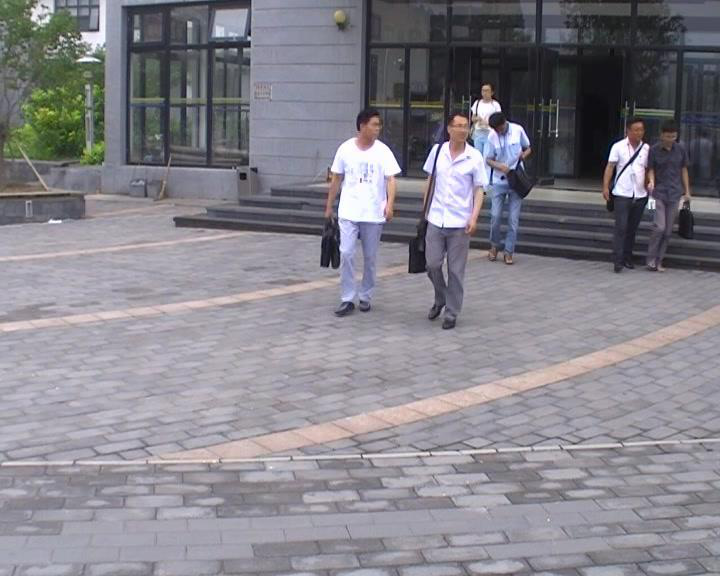

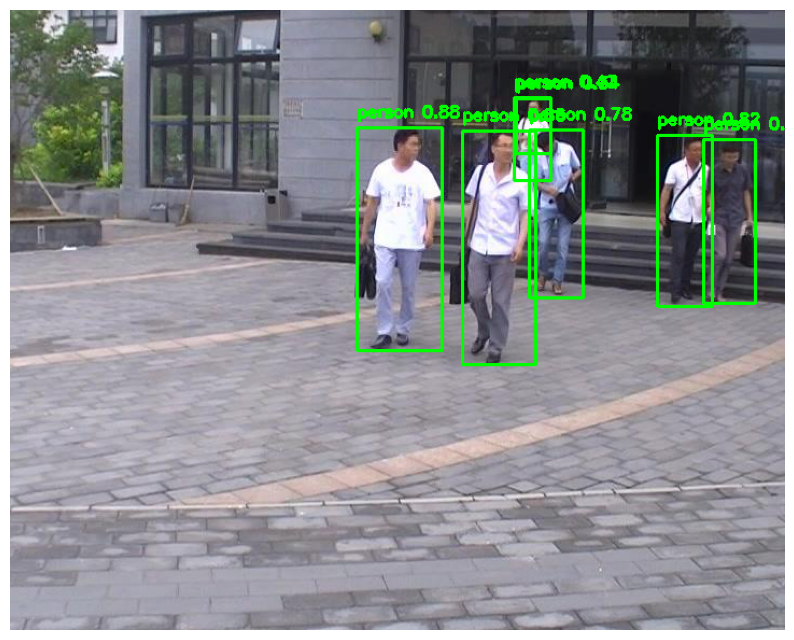

In [23]:
# Lets now use yolo to detect people in the image
# --- IGNORE ---
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
# --- IGNORE ---
# model = torch.hub.load('ultralytics/yolov5', 'yolov5s')  # load pretrained YOLOv5s model
from ultralytics import YOLO
model = YOLO("yolov5s.pt")


# all_detections = [detection[0] for detection in model(all_image_files)]


results = model(image)


r = results[0]
print(r.boxes)
display(image)


import pandas as pd

boxes = r.boxes
df = pd.DataFrame({
    "xmin": boxes.xyxy[:, 0].cpu().numpy(),
    "ymin": boxes.xyxy[:, 1].cpu().numpy(),
    "xmax": boxes.xyxy[:, 2].cpu().numpy(),
    "ymax": boxes.xyxy[:, 3].cpu().numpy(),
    "confidence": boxes.conf.cpu().numpy(),
    "class": boxes.cls.cpu().numpy(),
    "name": [r.names[int(c)] for c in boxes.cls]
})



persons = df[df["name"] == "person"]
# print(f"Number of people detected: {len(persons)}")

# lets draw bounding boxes on the image
image_cv = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)
for _, row in persons.iterrows():
    x1, y1, x2, y2 = int(row["xmin"]), int(row["ymin"]), int(row["xmax"]), int(row["ymax"])
    confidence = row["confidence"]
    cv2.rectangle(image_cv, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(image_cv, f"person {confidence:.2f}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image_cv, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()




In [61]:
persons

,xmin,ymin,xmax,ymax,confidence,class,name
0,265.739227,345.311737,342.589417,571.583557,0.772699,0.0,person
2,1626.654907,399.913147,1682.471313,460.398010,0.450517,0.0,person
5,543.661682,405.818207,590.887939,519.640930,0.341594,0.0,person
11,1624.408813,401.567413,1681.939087,481.969574,0.278597,0.0,person


In [63]:
# now since we have detected people in the image, we can now proceed by getting their embeddings using a pre-trained model like OpenPose or any other model of your choice. so pass
#  the bounding boxes to the model and get the embeddings for each person detected in the image.
#  we can use resnet for this purpose.

model = torch.hub.load('pytorch/vision:v0.10.0', 'resnet50', pretrained=True)
model.eval()
from torchvision import transforms
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
embeddings = []
for _, row in persons.iterrows():
    x1, y1, x2, y2 = int(row["xmin"]), int(row["ymin"]), int(row["xmax"]), int(row["ymax"])
    person_img = image.crop((x1, y1, x2, y2))
    input_tensor = preprocess(person_img)
    input_batch = input_tensor.unsqueeze(0)  # create a mini-batch as expected by the model
    with torch.no_grad():
        output = model(input_batch)
    embeddings.append(output[0].cpu().numpy())
embeddings




Downloading: "https://github.com/pytorch/vision/zipball/v0.10.0" to /home/saad/.cache/torch/hub/v0.10.0.zip
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /home/saad/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:26<00:00, 3.90MB/s]


[array([     4.5834,    -0.10388,     -1.6996,     0.41054,    -0.92927,    -0.54026,     -3.8278,    -0.37802,     -1.2831,     -1.7126,      1.1373,     -2.6502,    -0.48773,     -1.5897,    -0.67549,     -1.3255,    -0.70528,    -0.47145,     -3.2952,    -0.49411,     -2.4338,    -0.35518,     -2.4668,     -1.7568,
           -0.56475,     -2.2533,     0.45062,    -0.89772,      0.4496,      1.2533,     -2.0403,     -2.4801,     0.31365,    -0.54066,    -0.11668,    -0.78348,    -0.67027,     -2.3028,    -0.84017,     -1.0783,     -1.7485,      1.4039,     -1.2954,      2.9005,      0.5477,     -1.4761,     -2.9782,     -0.9204,
            -1.0906,     -2.8259,     -2.4491,      2.2062,       1.484,    -0.81088,    -0.46245,     -2.6165,     -2.8744,     -1.4879,     -1.5748,      1.9081,     0.78735,     -0.9153,      3.0094,      3.3143,   -0.011989,     -0.9584,    -0.23123,    -0.67891,      1.5326,     -2.8948,     -2.6038,    -0.46306,
            -2.2771,      1.0321,     -3

In [66]:
len(embeddings)

4

In [67]:
# now all that we need is a similarity metric for retrieving similar people across different images.so given for a query embedding, we can compute the similarity between the query embedding and all other embeddings using cosine similarity.
from sklearn.metrics.pairwise import cosine_similarity
# compute cosine similarity between all pairs of embeddings
similarity_matrix = cosine_similarity(embeddings)
similarity_matrix

array([[          1,     0.55718,     0.40012,     0.63043],
       [    0.55718,           1,     0.13792,      0.9066],
       [    0.40012,     0.13792,           1,     0.26915],
       [    0.63043,      0.9066,     0.26915,           1]], dtype=float32)